In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("/Users/theerdhasjoy/BIA/ML/Dataset/linear_regression_housing_practice.csv")
df.head()

,area_sqft,bedrooms,bathrooms,age_years,distance_to_city_km,parking,furnishing_status,price
0,1460,1,1.0,0,26.3,Yes,Furnished,461996.0
1,1894,1,3.0,29,23.7,Yes,Furnished,227579.0
2,1730,5,3.0,2,17.4,Yes,Semi-Furnished,1064953.0
3,1695,3,2.0,13,22.4,No,Unfurnished,302465.0
4,2238,3,2.0,29,26.5,Yes,Unfurnished,229371.0


In [3]:
# EDA

print(df.shape)
print("\n")
print(df.columns)
print("\n")
print(df.isnull().sum())
print("\n")
print(df.duplicated().sum())
print("\n")
print(df.nunique())
print("\n")
print(df.info())
print("\n")
print(df.describe())




(503, 8)


Index(['area_sqft', 'bedrooms', 'bathrooms', 'age_years',
       'distance_to_city_km', 'parking', 'furnishing_status', 'price'],
      dtype='str')


area_sqft               0
bedrooms                0
bathrooms              10
age_years               0
distance_to_city_km     0
parking                 0
furnishing_status       8
price                   0
dtype: int64


3


area_sqft              452
bedrooms                 5
bathrooms                3
age_years               40
distance_to_city_km    241
parking                  2
furnishing_status        3
price                  500
dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 503 entries, 0 to 502
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_sqft            503 non-null    int64  
 1   bedrooms             503 non-null    int64  
 2   bathrooms            493 non-null    float64
 3   age_years            503 non-nul

In [4]:
num_cols = df.select_dtypes(include= np.number).columns.tolist()
cat_cols = df.select_dtypes(include = "object").columns.tolist()

print(f"numerical columns are : {num_cols}")
print(f"categorical columns are : {cat_cols}")

numerical columns are : ['area_sqft', 'bedrooms', 'bathrooms', 'age_years', 'distance_to_city_km', 'price']
categorical columns are : ['parking', 'furnishing_status']


/var/folders/y5/lf_stmcj5nv2hnzy3q1b5pb80000gn/T/ipykernel_53121/2995993668.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include = "object").columns.tolist()


In [5]:
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mean())

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])



In [6]:
df.isnull().sum()

area_sqft              0
bedrooms               0
bathrooms              0
age_years              0
distance_to_city_km    0
parking                0
furnishing_status      0
price                  0
dtype: int64

In [7]:
df["parking"] = df["parking"].map({
    "No" : 0,
    "Yes" : 1
})

In [8]:
df = pd.get_dummies(
    df,
    columns= ["furnishing_status"],
    dtype= int
)

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns= "price")
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state= 42
)

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

model = LinearRegression()

model.fit(X_train_scaled, y_train)
pred = model.predict(X_test_scaled)

print(f"MAE : {mean_absolute_error(y_test, pred):,.0f}\n")
print(f"R2 : {r2_score(y_test, pred):.3f}\n")
print(f"MSE : {mean_squared_error(y_test, pred):,.0f}\n")





MAE : 200,364

R2 : 0.620

MSE : 62,180,405,655



In [19]:
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f"RMSE : {rmse}")

RMSE : 249359.99208991262


In [21]:
train_pred = model.predict(X_train_scaled)

print(f"Train R2 : {r2_score(y_train, train_pred)}")
print(f"Test R2  : {r2_score(y_test, pred)}")

Train R2 : 0.6891518512363506
Test R2  : 0.620229673478271


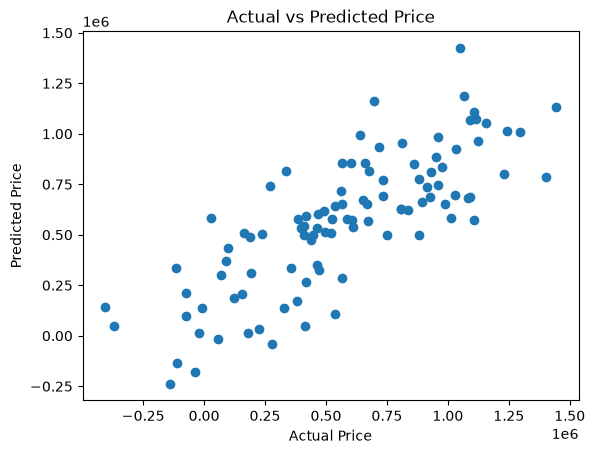

In [23]:
import matplotlib.pyplot as plt

plt.scatter(y_test, pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

plt.show()

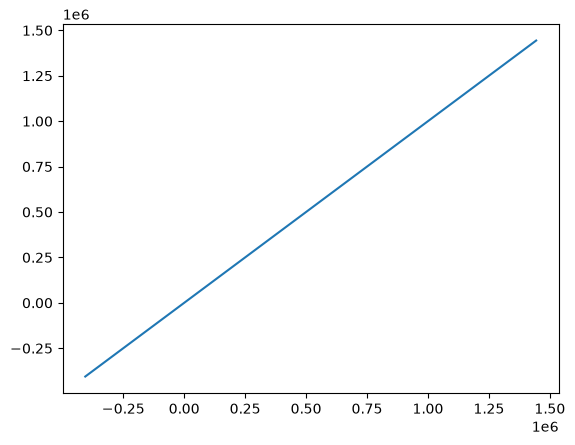

In [24]:
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)